<a href="https://colab.research.google.com/github/mipaillafil/evaluacion-1-gp/blob/main/Mall_Customers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Segmentación de Clientes de Centros Comerciales mediante Machine Learning**
**Integrantes:** Kimberly Bobadilla, Luna Cortés, Javiera Marchesse y Millaray Paillafil

##**1. Importar Librerias**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

##**2. Cargar Dataset**

In [ ]:
url = "https://raw.githubusercontent.com/mipaillafil/evaluacion-1-gp/main/Mall%20Customers.xlsx"
df = pd.read_excel(url)
df.head(5)

,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


##**3. Información General**




In [ ]:
print(f"Cantidad de registros: {len(df)}")
print(f"Cantidad de columnas: {df.shape[1]}")
print(f"Nombre de las columnas: {df.columns.to_list()}")
print(f"Cantidad de registros duplicados: {df.duplicated().sum()}")

Cantidad de registros: 200
Cantidad de columnas: 7
Nombre de las columnas: ['CustomerID', 'Gender', 'Age', 'Education ', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']
Cantidad de registros duplicados: 0


In [ ]:
print(f"Información del dataset:")
print(df.info())

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Education               200 non-null    object
 4   Marital Status          200 non-null    object
 5   Annual Income (k$)      200 non-null    int64 
 6   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 11.1+ KB
None


In [ ]:
print("Estadisticas descriptivas:")
print(df.describe())

Estadisticas descriptivas:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


##**4. Revisión de Valores Nulos**

In [ ]:
#Convertir valores Unknown a Nulos

#Contar los valores Unknown
print("\nValores Unknown encontrados:")

for columna in df.columns:
    # Calcula la cantidad de valores 'Unknown' en la columna actual
    cantidad_unknown = (
        df[columna]
        .astype(str) # Convierte la columna a tipo string para asegurar la comparación
        .str.strip() # Elimina espacios en blanco al inicio y final de las cadenas
        .str.lower() # Convierte las cadenas a minúsculas para una comparación uniforme
        .eq("unknown") # Compara si el valor es igual a "unknown"
        .sum() # Suma todas las coincidencias para obtener la cantidad total
    )

    if cantidad_unknown > 0:
        print(f"{columna}: {cantidad_unknown}")


Valores Unknown encontrados:
Education : 26
Marital Status: 15


In [ ]:
#Convertir Unknown a NaN
df = df.replace(["Unknown", "unknown", "UNKNOWN"], np.nan )

In [ ]:
#Mostrar cantidad de valores nulos despues de la conversion
print(f"Valores nulos después de la conversión: \n{df.isnull().sum()}") # Muestra el recuento de valores nulos por columna después de la conversión
print(f"\nPorcentaje de valores nulos: \n{(df.isnull().mean()* 100).round(2)}") # Muestra el porcentaje de valores nulos por columna, redondeado a 2 decimales

Valores nulos después de la conversión: 
CustomerID                 0
Gender                     0
Age                        0
Education                 26
Marital Status            15
Annual Income (k$)         0
Spending Score (1-100)     0
dtype: int64

Porcentaje de valores nulos: 
CustomerID                 0.0
Gender                     0.0
Age                        0.0
Education                 13.0
Marital Status             7.5
Annual Income (k$)         0.0
Spending Score (1-100)     0.0
dtype: float64


##**5. Distribución por Género**

In [ ]:
genero = df["Gender"].value_counts()
print(genero)

Gender
F    112
M     88
Name: count, dtype: int64


In [ ]:
#Distribución porcentual por Género
print(
    f"Porcentaje: "
    f"{df['Gender'].value_counts(normalize=True).mul(100).round(2)}"
) # Calcula y muestra la distribución porcentual de la columna 'Gender', redondeada a 2 decimales

Porcentaje: Gender
F    56.0
M    44.0
Name: proportion, dtype: float64


##**6. Estandarización**

In [ ]:
#Variables utilizadas para la segmentacion
variables = ["Annual Income (k$)", "Spending Score (1-100)"]
print(variables)

['Annual Income (k$)', 'Spending Score (1-100)']


In [ ]:
X = df[variables].copy()
scaler = StandardScaler() # Inicializa un objeto StandardScaler para escalar los datos
X_scaled = scaler.fit_transform(X) # Ajusta el escalador a los datos `X` y luego los transforma (estandariza)

##**7. Determinar el número de clusters**

In [ ]:
resultados_silhouette = {}

for k in range(2,9):
  modelo = KMeans(
      n_clusters=k,
      random_state=42, # Fija la semilla aleatoria para reproducibilidad
      n_init=20) # Número de veces que el algoritmo k-means se ejecutará con diferentes semillas de centroides

  etiquetas = modelo.fit_predict(X_scaled) # Entrena el modelo KMeans con los datos escalados y asigna cada punto a un cluster

 # Calcula el Silhouette Score para la agrupación actual
  score = silhouette_score(X_scaled, etiquetas)

  resultados_silhouette[k] = score # Almacena el Silhouette Score en el diccionario, usando k como clave

# Imprime el valor de k y su correspondiente Silhouette Score
  print(
      f"k = {k}"
      f"-> Silhouette = {score:.4f}"
  )

k = 2-> Silhouette = 0.3213
k = 3-> Silhouette = 0.4666
k = 4-> Silhouette = 0.4939
k = 5-> Silhouette = 0.5547
k = 6-> Silhouette = 0.5399
k = 7-> Silhouette = 0.5281
k = 8-> Silhouette = 0.4567


##**8. Seleccionar el mejor K**

In [ ]:
mejor_k = max(resultados_silhouette, key=resultados_silhouette.get) # Encuentra la clave (valor de k) con el Silhouette Score más alto
mejor_score = resultados_silhouette[mejor_k] # Obtiene el Silhouette Score correspondiente al mejor k

print(f"Mejor cantidad de clusters: {mejor_k}")
print(f"Mejor Silhouette Score: {round(mejor_score, 4)}")

Mejor cantidad de clusters: 5
Mejor Silhouette Score: 0.5547


##**9. Grafico del Silhouette**

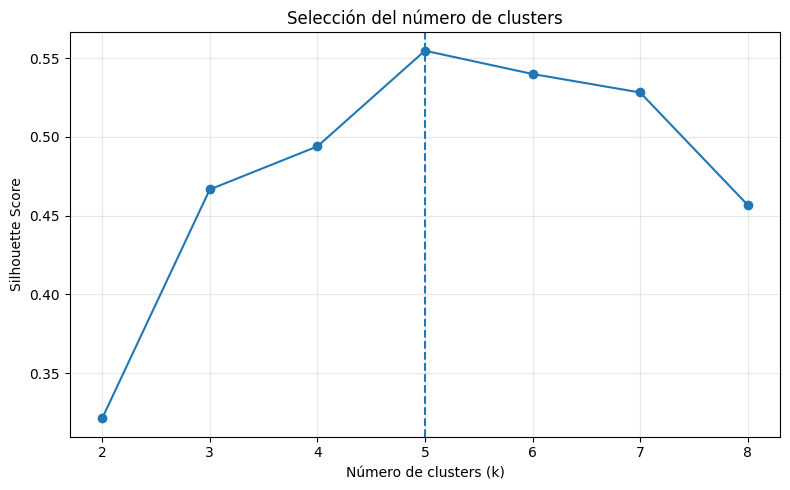

In [ ]:
plt.figure(figsize=(8, 5))

# Dibuja una línea en el gráfico
plt.plot(
    list(resultados_silhouette.keys()),
    list(resultados_silhouette.values()),
    marker="o"
)

# Dibuja una línea vertical en el gráfico
plt.axvline(
    mejor_k,
    linestyle="--"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Selección del número de clusters")
plt.xticks(range(2, 9)) # Establece las marcas del eje X para ir de 2 a 8
plt.grid(alpha=0.3)
plt.tight_layout() # Ajusta automáticamente los parámetros del gráfico para un diseño ajustado
plt.savefig("silhouette.png",dpi=200
)
plt.show()

El análisis de Silhouette evaluó valores de K entre 2 y 8. El mejor resultado se obtuvo con K=5, alcanzando un Silhouette Score de 0,5547. Por lo tanto, se seleccionaron cinco segmentos de clientes. El valor obtenido indica una separación razonable entre los grupos identificados.

##**10. Crear el modelo K-Means Final**

In [ ]:
modelo_final = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=20) # Número de veces que el algoritmo k-means se ejecutará con diferentes semillas de centroides

df["Cluster"] = modelo_final.fit_predict(X_scaled)

##**11. Centroides**

In [ ]:
centroides = scaler.inverse_transform(modelo_final.cluster_centers_) # Transforma los centroides de vuelta a la escala original de los datos
centroides_df = pd.DataFrame(centroides, columns = variables) # Crea un DataFrame con los centroides, usando los nombres de las variables originales

print(f"Centroides de los clusters: \n{centroides_df.round(2)}")

Centroides de los clusters: 
   Annual Income (k$)  Spending Score (1-100)
0               55.30                   49.52
1               86.54                   82.13
2               25.73                   79.36
3               88.20                   17.11
4               26.30                   20.91


##**12. Resumen de Clusters**


In [ ]:
resumen_clusters = (
    df.groupby("Cluster") # Agrupa el DataFrame original por la columna 'Cluster'
    .agg( # Realiza agregaciones en los grupos
        Clientes = ("CustomerID", "count"), # Cuenta el número de clientes en cada cluster
        Edad_promedio = ("Age", "mean"), # Calcula la edad promedio en cada cluster
        Ingreso_promedio = ("Annual Income (k$)", "mean"), # Calcula el ingreso anual promedio en cada cluster
        Spending_promedio = ("Spending Score (1-100)", "mean") # Calcula el spending score promedio en cada cluster
        )
    .reset_index() # Restablece el índice del DataFrame resultante
)

# Calcular porcentaje de clientes por cluster
resumen_clusters["Porcentaje"] = ( # Crea una nueva columna 'Porcentaje' en el DataFrame resumen_clusters
    resumen_clusters["Clientes"] / len(df) * 100 # Calcula el porcentaje de clientes en cada cluster respecto al total
).round(2)

print(f"Resumen de Segmentos:\n{resumen_clusters.round(2)}")

Resumen de Segmentos:
   Cluster  Clientes  Edad_promedio  Ingreso_promedio  Spending_promedio  \
0        0        81          42.72             55.30              49.52   
1        1        39          32.69             86.54              82.13   
2        2        22          25.27             25.73              79.36   
3        3        35          41.11             88.20              17.11   
4        4        23          45.22             26.30              20.91   

   Porcentaje  
0        40.5  
1        19.5  
2        11.0  
3        17.5  
4        11.5  


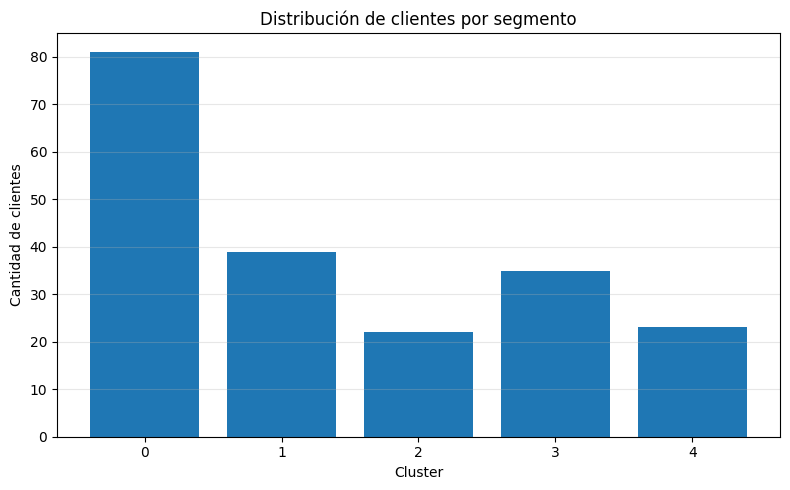

In [ ]:
#Cantidad de clientes por clusters
plt.figure(figsize=(8, 5))
plt.bar(
    resumen_clusters["Cluster"].astype(str), # Eje X: los nombres de los clusters (convertidos a string)
    resumen_clusters["Clientes"] # Eje Y: la cantidad de clientes en cada cluster
)

plt.xlabel("Cluster")
plt.ylabel("Cantidad de clientes")
plt.title("Distribución de clientes por segmento")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout() # Ajusta automáticamente los parámetros del gráfico para un diseño ajustado
plt.savefig("distribucion_clusters.png", dpi=200) # Guarda el gráfico como un archivo de imagen
plt.show()

###**Auditoria por genero en clusters**

In [ ]:
auditoria_genero = pd.crosstab(
    df["Cluster"],
    df["Gender"],
    normalize="index"
).mul(100).round(2)

print("Distribución porcentual de género por cluster:")
auditoria_genero

Distribución porcentual de género por cluster:


Gender,F,M
Cluster,,
0,59.26,40.74
1,53.85,46.15
2,59.09,40.91
3,45.71,54.29
4,60.87,39.13


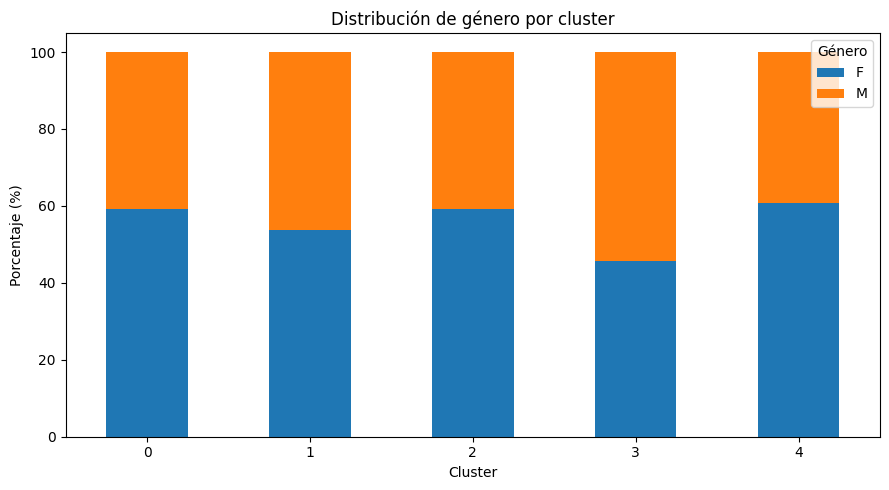

In [ ]:
auditoria_genero.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Porcentaje (%)")
plt.title("Distribución de género por cluster")
plt.legend(title="Género")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("auditoria_genero.png", dpi=200)
plt.show()

**Explicación:**

La auditoría muestra que todos los clusters tienen representación de ambos géneros. Los Clusters 0, 2 y 4 presentan una mayor proporción de mujeres, mientras que el Cluster 3 presenta una mayor proporción de hombres. Estas diferencias no implican discriminación, ya que el género no fue utilizado para crear los clusters, sino únicamente para evaluar posibles diferencias de representación.

###**Auditoria Nivel Educativo**

In [ ]:
auditoria_educacion = pd.crosstab(
    df["Cluster"],
    df["Education "],
    normalize="index"
).mul(100).round(2)

print("Distribución porcentual de educación por cluster:")
print(auditoria_educacion)

Distribución porcentual de educación por cluster:
Education   College  Doctorate  Graduate  High School  Post-Graduate  \
Cluster                                                                
0              7.25       8.70     44.93        23.19           4.35   
1             11.43       5.71     37.14        17.14           5.71   
2             12.50       6.25     43.75        25.00           0.00   
3             11.76       2.94     23.53        29.41           5.88   
4             10.00       5.00     40.00        20.00           5.00   

Education   Uneducated  
Cluster                 
0                11.59  
1                22.86  
2                12.50  
3                26.47  
4                20.00  


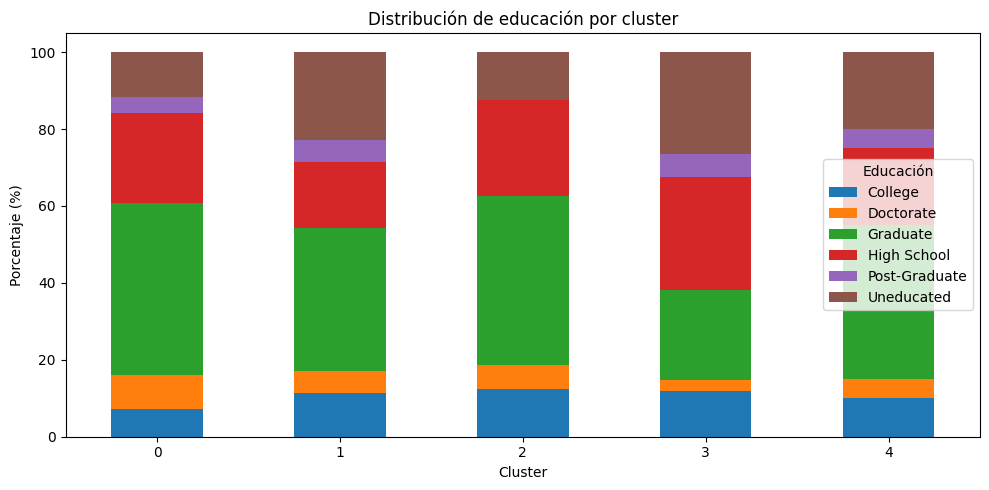

In [ ]:
auditoria_educacion.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Porcentaje (%)")
plt.title("Distribución de educación por cluster")
plt.legend(title="Educación")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("auditoria_educacion.png", dpi=200)
plt.show()

**Explicación:**

La auditoría muestra diferencias en los niveles de educación entre los clusters. En todos los segmentos predomina la categoría Graduate, aunque su proporción varía entre grupos. También se observan diferencias en las categorías High School, College y Uneducated.

###**Auditoría de estado civil por cluster**

In [ ]:
auditoria_estado_civil = pd.crosstab(
    df["Cluster"],
    df["Marital Status"],
    normalize="index"
).mul(100).round(2)

print("Auditoría de estado civil por cluster:")
print(auditoria_estado_civil)

Auditoría de estado civil por cluster:
Marital Status  Divorced  Married  Single
Cluster                                  
0                   6.58    57.89   35.53
1                  10.81    62.16   27.03
2                   0.00    66.67   33.33
3                   5.88    61.76   32.35
4                   5.00    60.00   35.00


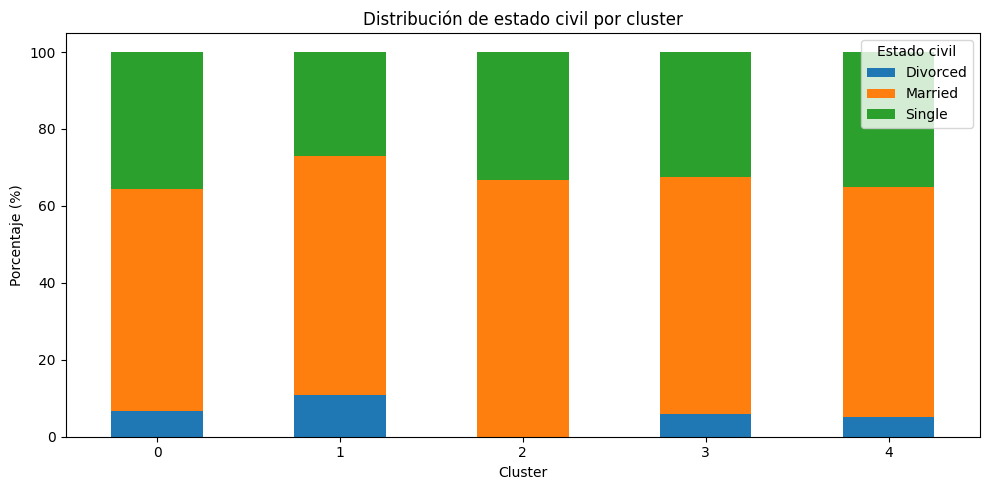

In [ ]:
auditoria_estado_civil.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Porcentaje (%)")
plt.title("Distribución de estado civil por cluster")
plt.legend(title="Estado civil")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("auditoria_estado_civil.png", dpi=200)
plt.show()

**Explicación:**

El gráfico muestra diferencias en la distribución del estado civil entre los clusters. En todos los segmentos predomina la categoría Married, seguida por Single, mientras que Divorced presenta una proporción menor y no aparece en el Cluster 2.

##**13. Interpretación de los Clusters**

In [ ]:
# Puntos de corte calculados a partir del dataset
mediana_ingreso = df["Annual Income (k$)"].median()
mediana_gasto = df["Spending Score (1-100)"].median()

print(f"Mediana de ingreso: {mediana_ingreso:.2f} k$")
print(f"Mediana de gasto: {mediana_gasto:.2f}")


def interpretar_cluster(fila):
    ingreso = fila["Ingreso_promedio"]
    gasto = fila["Spending_promedio"]

    if ingreso >= mediana_ingreso and gasto >= mediana_gasto:
        return "Alto ingreso / Alto gasto"

    elif ingreso >= mediana_ingreso and gasto < mediana_gasto:
        return "Alto ingreso / Bajo gasto"

    elif ingreso < mediana_ingreso and gasto >= mediana_gasto:
        return "Bajo ingreso / Alto gasto"

    else:
        return "Bajo ingreso / Bajo gasto"


resumen_clusters["Segmento"] = (
    resumen_clusters.apply(interpretar_cluster, axis=1)
)

print("Interpretación de los clusters:")
display(
    resumen_clusters[
        [
            "Cluster",
            "Clientes",
            "Porcentaje",
            "Ingreso_promedio",
            "Spending_promedio",
            "Segmento"
        ]
    ].round(2)
)

Mediana de ingreso: 61.50 k$
Mediana de gasto: 50.00
Interpretación de los clusters:


,Cluster,Clientes,Porcentaje,Ingreso_promedio,Spending_promedio,Segmento
0,0,81,40.5,55.30,49.52,Bajo ingreso / Bajo gasto
1,1,39,19.5,86.54,82.13,Alto ingreso / Alto gasto
2,2,22,11.0,25.73,79.36,Bajo ingreso / Alto gasto
3,3,35,17.5,88.20,17.11,Alto ingreso / Bajo gasto
4,4,23,11.5,26.30,20.91,Bajo ingreso / Bajo gasto


Nota: La clasificación mediante medianas permite interpretar los clusters según su posición relativa respecto de la muestra. Debido a que dos clusters pueden ubicarse en el mismo cuadrante, las etiquetas deben complementarse con sus centroides y tamaño para distinguir sus características.

##**14. Gráfico de Segmentación**

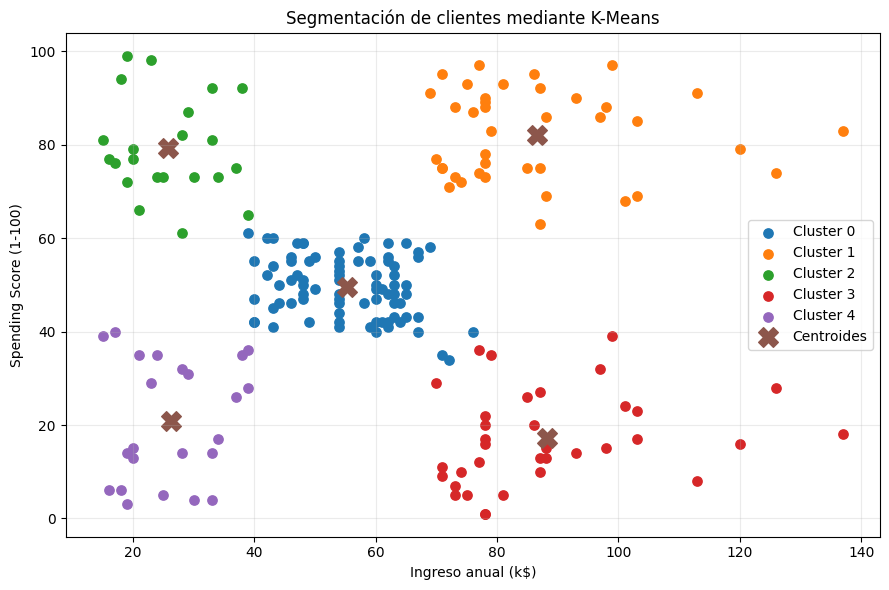

In [ ]:
plt.figure(figsize=(9, 6))

for cluster in sorted(
    df["Cluster"].unique()):
    datos_cluster = df[
        df["Cluster"] == cluster]

    plt.scatter(
        datos_cluster["Annual Income (k$)"],
        datos_cluster["Spending Score (1-100)"],
        s=45, # Tamaño de los puntos
        label=f"Cluster {cluster}")

# Mostrar centroides
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=200, # Tamaño de los marcadores (más grandes para los centroides)
    label="Centroides"
)
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Segmentación de clientes mediante K-Means")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("segmentacion.png", dpi=200) # Guarda el gráfico como un archivo de imagen
plt.show()

**Explicación:**

El algoritmo identificó cinco segmentos de clientes con diferentes combinaciones de ingreso anual y comportamiento de gasto, permitiendo orientar estrategias comerciales diferenciadas.

## Conclusión del análisis

El análisis mediante K-Means permitió identificar cinco segmentos de clientes con características diferenciadas según su nivel de ingreso anual y nivel de gasto. Para determinar la cantidad de grupos se evaluaron valores de K entre 2 y 8 mediante el Silhouette Score, seleccionándose **K = 5**, que obtuvo el mejor resultado con un valor de **0,5547**.

La segmentación se construyó utilizando únicamente las variables **Annual Income (k$)** y **Spending Score (1-100)**, previamente estandarizadas. La variable CustomerID fue excluida por corresponder únicamente a un identificador. Las variables **Age, Gender, Education y Marital Status** se utilizaron posteriormente para complementar la caracterización y realizar auditorías de los clusters.

Los resultados muestran diferencias entre los grupos en términos de ingreso y gasto, permitiendo identificar perfiles como clientes de alto ingreso y alto gasto, bajo ingreso y alto gasto, alto ingreso y bajo gasto, además de segmentos con niveles de gasto e ingreso más bajos. Sin embargo, los clusters representan agrupaciones estadísticas y no una clasificación definitiva del comportamiento individual de los clientes.

Finalmente, los resultados deben utilizarse como una herramienta de apoyo para la toma de decisiones. Se recomienda mantener una revisión periódica de la calidad y representatividad de los datos, realizar auditorías de posibles sesgos y mantener supervisión humana antes de utilizar la segmentación en decisiones comerciales.

##**15. Implementación técnica**
En esta sección se agregan las etapas de preparación, separación de datos, evaluación, generación de cinco predicciones y automatización. Se conserva el análisis anterior.

Como este proyecto utiliza K-Means, corresponde a un aprendizaje no supervisado: no existe una variable dependiente objetivo como en una clasificación supervisada. Se agrupan los clientes usando ingreso anual y puntuación de gasto.

In [ ]:
print("Tamaño del dataset:", df.shape)
print("Columnas:", df.columns.to_list())
print("\\nValores nulos por columna:")
print(df[["Annual Income (k$)", "Spending Score (1-100)"]].isnull().sum())


Tamaño del dataset: (200, 8)
Columnas: ['CustomerID', 'Gender', 'Age', 'Education ', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']
\nValores nulos por columna:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


###**15.2 Analizar las variables y generar gráficos representativos**
En K-Means no hay clases previamente definidas. Por eso, se revisa la distribución de las dos variables numéricas utilizadas para formar los segmentos: ingreso anual y puntuación de gasto.

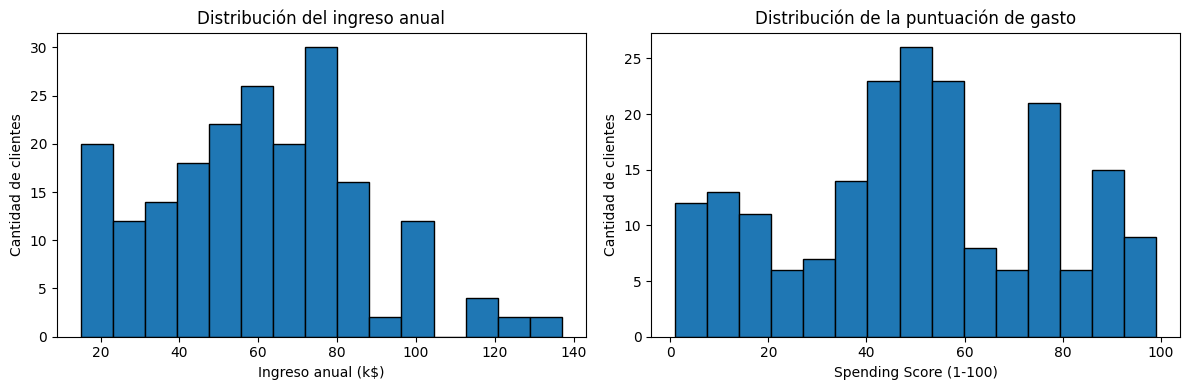

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].hist(df["Annual Income (k$)"], bins=15, edgecolor="black")
ejes[0].set_title("Distribución del ingreso anual")
ejes[0].set_xlabel("Ingreso anual (k$)")
ejes[0].set_ylabel("Cantidad de clientes")

ejes[1].hist(df["Spending Score (1-100)"], bins=15, edgecolor="black")
ejes[1].set_title("Distribución de la puntuación de gasto")
ejes[1].set_xlabel("Spending Score (1-100)")
ejes[1].set_ylabel("Cantidad de clientes")

plt.tight_layout()
plt.show()


15.3 Preparar los datos y seleccionar las variables
Las variables independientes de entrada son Annual Income (k$) y Spending Score (1-100). Como K-Means es no supervisado, no se define una variable dependiente. Se separan únicamente las variables que utilizará el algoritmo.

In [ ]:
X_modelo = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("Variables usadas por K-Means:")
print(X_modelo.columns.to_list())
print("Registros disponibles:", len(X_modelo))


Variables usadas por K-Means:
['Annual Income (k$)', 'Spending Score (1-100)']
Registros disponibles: 200


###**15.4 Separar los datos en entrenamiento y prueba**
Se utiliza el 80 % para entrenamiento y el 20 % para prueba. El escalador se ajusta solamente con entrenamiento y luego transforma prueba, para evitar usar información del conjunto de prueba durante el ajuste.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_entrenamiento, X_prueba = train_test_split(
    X_modelo,
    test_size=0.20,
    random_state=42
)

escalador_validacion = StandardScaler()
X_entrenamiento_escalado = escalador_validacion.fit_transform(X_entrenamiento)
X_prueba_escalado = escalador_validacion.transform(X_prueba)

print("Registros de entrenamiento:", len(X_entrenamiento))
print("Registros de prueba:", len(X_prueba))


Registros de entrenamiento: 160
Registros de prueba: 40


###**15.5 Entrenar y revisar el modelo**
Se entrena un modelo K-Means usando la cantidad de clusters seleccionada anteriormente. Como no hay etiquetas verdaderas para comparar, se utiliza el Silhouette Score como métrica interna de separación y cohesión de los grupos.

In [ ]:
modelo_validacion = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=20
)

etiquetas_entrenamiento = modelo_validacion.fit_predict(X_entrenamiento_escalado)
etiquetas_prueba = modelo_validacion.predict(X_prueba_escalado)

silhouette_entrenamiento = silhouette_score(
    X_entrenamiento_escalado,
    etiquetas_entrenamiento
)
silhouette_prueba = silhouette_score(
    X_prueba_escalado,
    etiquetas_prueba
)

print(f"Cantidad de clusters: {mejor_k}")
print(f"Silhouette en entrenamiento: {silhouette_entrenamiento:.4f}")
print(f"Silhouette en prueba: {silhouette_prueba:.4f}")


Cantidad de clusters: 5
Silhouette en entrenamiento: 0.5518
Silhouette en prueba: 0.5668


Interpretación: el Silhouette Score permite revisar si los grupos están relativamente separados. Un valor más cercano a 1 indica grupos más definidos; un valor cercano a 0 indica que algunos clientes están entre grupos. Esta evaluación es interna, porque el dataset no incluye una clase correcta de segmento para comparar.

###**15.5.1 Analizar si la preparación y el modelo fueron suficientes**
Para revisar si los pasos realizados fueron suficientes, se comparan los resultados de Silhouette de entrenamiento y prueba y se observa cuántos clientes quedaron en cada cluster del conjunto de prueba. Esta revisión ayuda a detectar grupos poco separados o clusters con pocos registros. Como es aprendizaje no supervisado, la métrica no mide aciertos contra una respuesta correcta.

In [ ]:
# Cantidad de clientes asignados a cada cluster en entrenamiento y prueba
resumen_entrenamiento = pd.Series(etiquetas_entrenamiento).value_counts().sort_index()
resumen_prueba = pd.Series(etiquetas_prueba).value_counts().sort_index()

resumen_validacion = pd.DataFrame({
    "Clientes_entrenamiento": resumen_entrenamiento,
    "Clientes_prueba": resumen_prueba
}).fillna(0).astype(int)

print("Distribución de clusters en los datos separados:")
display(resumen_validacion)

diferencia_silhouette = abs(
    silhouette_entrenamiento - silhouette_prueba
)
print(f"Diferencia entre Silhouette de entrenamiento y prueba: {diferencia_silhouette:.4f}")

if silhouette_prueba >= 0.50:
    print("Evaluación: en prueba, los grupos muestran una separación razonable según Silhouette.")
elif silhouette_prueba >= 0.25:
    print("Evaluación: en prueba, la separación de los grupos es moderada; conviene revisar los perfiles y gráficos.")
else:
    print("Evaluación: en prueba, la separación es débil; se recomienda revisar las variables y la cantidad de clusters.")

if diferencia_silhouette > 0.15:
    print("También existe una diferencia apreciable entre entrenamiento y prueba, por lo que conviene revisar la estabilidad de los grupos.")
else:
    print("Los valores de entrenamiento y prueba son relativamente similares, aunque esto no garantiza por sí solo que el modelo sea perfecto.")

Distribución de clusters en los datos separados:


,Clientes_entrenamiento,Clientes_prueba
0,20,3
1,63,18
2,24,11
3,19,3
4,34,5


Diferencia entre Silhouette de entrenamiento y prueba: 0.0150
Evaluación: en prueba, los grupos muestran una separación razonable según Silhouette.
Los valores de entrenamiento y prueba son relativamente similares, aunque esto no garantiza por sí solo que el modelo sea perfecto.


**Conclusión técnica:** los pasos realizados permiten construir y revisar una segmentación inicial. La suficiencia se determina observando Silhouette, la distribución de clientes y los gráficos anteriores. K-Means no predice una clase real ni demuestra causalidad; los segmentos deben interpretarse junto con los centroides y el contexto del negocio.

###**15.6 Generar cinco predicciones con clientes nuevos**
Se crean cinco ejemplos de clientes con valores de ingreso anual y puntuación de gasto. El modelo asigna cada ejemplo al cluster más cercano. Los valores son ejemplos de prueba y no corresponden a clientes reales adicionales del archivo.

In [ ]:
nuevos_clientes = pd.DataFrame({
    "Annual Income (k$)": [20, 35, 60, 85, 120],
    "Spending Score (1-100)": [20, 80, 50, 90, 30]
})

nuevos_clientes_escalados = scaler.transform(nuevos_clientes[variables])
predicciones = modelo_final.predict(nuevos_clientes_escalados)

resultado_predicciones = nuevos_clientes.copy()
resultado_predicciones["Cluster_predicho"] = predicciones

print("Cinco predicciones para nuevos clientes:")
display(resultado_predicciones)


Cinco predicciones para nuevos clientes:


,Annual Income (k$),Spending Score (1-100),Cluster_predicho
0,20,20,4
1,35,80,2
2,60,50,0
3,85,90,1
4,120,30,3


###**15.7 Proponer e implementar una automatización**
Se crea una función para recibir los datos de un nuevo cliente, aplicar el mismo escalado usado por el modelo final y devolver el cluster asignado. Así se puede reutilizar la segmentación sin repetir manualmente todos los pasos.

In [ ]:
def segmentar_nuevos_clientes(datos_nuevos):
    # Comprobar que estén presentes las dos variables necesarias
    columnas_requeridas = variables
    faltantes = [col for col in columnas_requeridas if col not in datos_nuevos.columns]

    if faltantes:
        raise ValueError(f"Faltan estas columnas: {faltantes}")

    # Preparar los datos y asignar el cluster
    datos_preparados = datos_nuevos[columnas_requeridas].copy()

    if datos_preparados.isnull().any().any():
        raise ValueError("Los datos nuevos no deben contener valores nulos.")

    datos_escalados = scaler.transform(datos_preparados)
    clusters = modelo_final.predict(datos_escalados)

    resultado = datos_preparados.copy()
    resultado["Cluster_predicho"] = clusters
    return resultado


# Prueba de la automatización con los cinco ejemplos anteriores
resultado_automatico = segmentar_nuevos_clientes(nuevos_clientes)
display(resultado_automatico)


,Annual Income (k$),Spending Score (1-100),Cluster_predicho
0,20,20,4
1,35,80,2
2,60,50,0
3,85,90,1
4,120,30,3


Resultado esperado de la automatización: al entregar ingreso anual y puntuación de gasto, la función devuelve una tabla con el cluster asignado a cada cliente. Esto permite reutilizar el modelo cuando se reciban nuevos registros.

###**15.7.1 Guardar automáticamente las predicciones**
Como paso adicional, se guardan las cinco asignaciones en un archivo CSV. Así, los resultados pueden compartirse con el equipo de marketing o utilizarse en otro análisis.

In [ ]:
archivo_resultados = "predicciones_nuevos_clientes.csv"
resultado_automatico.to_csv(archivo_resultados, index=False, encoding="utf-8-sig")
print(f"Archivo generado: {archivo_resultados}")
print("Cantidad de predicciones guardadas:", len(resultado_automatico))

Archivo generado: predicciones_nuevos_clientes.csv
Cantidad de predicciones guardadas: 5
